# UFO reports: duration and the calendar
IS445 · Independent second assignment · Terry Hu

Two original Altair/Vega-Lite views of the same cohort: US reports dated 2000–2013, with a positive numeric duration and one of the eight most common informative shape labels. This is a descriptive report archive, not evidence of extraterrestrial activity. Neither chart repeats the course's geographic scatterplots or duration-weighted maps.

[The Data](https://raw.githubusercontent.com/UIUC-iSchool-DataViz/is445_data/main/ufo-scrubbed-geocoded-time-standardized-00.csv) · [Interactive Jekyll page](https://terryhu2.github.io/hw5-ufo/) · [GitHub notebook](https://github.com/terryhu2/terryhu2.github.io/blob/main/second_assignment_ufo.ipynb)

Run all cells from a fresh kernel. Data is read from the URL, without local data files. Only pandas and Altair >=5 are required. Static PNG previews are optional when vl-convert-python is available; the interactive charts do not depend on that optional package.

In [1]:
import json
from pathlib import Path
import pandas as pd
import altair as alt
from IPython.display import display, Image

assert int(alt.__version__.split('.')[0]) >= 5, "This notebook requires Altair >=5."
DATA_URL = "https://raw.githubusercontent.com/UIUC-iSchool-DataViz/is445_data/main/ufo-scrubbed-geocoded-time-standardized-00.csv"
COLUMNS = ['date', 'city', 'state', 'country', 'shape', 'duration_seconds',
           'duration', 'comment', 'report_date', 'latitude', 'longitude']
# The allowed -00.csv file has NO header: names= preserves its first report.
raw = pd.read_csv(DATA_URL, names=COLUMNS, header=None, low_memory=False)
print(f"Python packages: pandas {pd.__version__}; Altair {alt.__version__}")
print(f"Source rows: {len(raw):,}")

Python packages: pandas 3.1.1; Altair 6.3.0
Source rows: 80,332


## One explicit cohort for both views
Normalize country and shape labels; parse only the calendar date, since some source times use 24:00. Invalid dates become missing rather than being invented. Convert duration to numeric, requiring a finite positive value. Keep US rows in the 14 complete calendar years 2000–2013. Exclude missing shape labels and the nonspecific labels unknown, other, and changed, then choose the eight most frequent remaining shapes, breaking ties alphabetically. Both charts use exactly this final cohort. No random sampling, duration cap, or duplicate removal is applied: the source supplies no unique report ID with which to establish duplicate identity. Narratives and coordinates are never included in exported chart data.

In [2]:
data = raw[['date', 'country', 'shape', 'duration_seconds']].copy()
for col in ['country', 'shape']:
    data[col] = data[col].astype('string').str.strip().str.lower()
data['day'] = pd.to_datetime(data['date'].str.split().str[0],
                             format='%m/%d/%Y', errors='coerce')
data['seconds'] = pd.to_numeric(data['duration_seconds'], errors='coerce')
valid = (data.country.eq('us').fillna(False)
         & data.day.dt.year.between(2000, 2013)
         & data.seconds.gt(0) & data.seconds.lt(float('inf'))
         & data['shape'].notna() & data['shape'].ne('')
         & ~data['shape'].isin(['unknown', 'other', 'changed']))
eligible = data.loc[valid].copy()
ranking = (eligible.groupby('shape').size().rename('reports').reset_index()
           .sort_values(['reports', 'shape'], ascending=[False, True]))
shapes = ranking.head(8)['shape'].tolist()
clean = eligible[eligible['shape'].isin(shapes)].copy()
clean['month'] = clean.day.dt.month.astype(int)
summary = (clean.groupby('shape')['seconds'].agg(
    reports='size', q1=lambda x: x.quantile(.25), median='median',
    q3=lambda x: x.quantile(.75)).reset_index())
shape_order = summary.sort_values(['median', 'shape'])['shape'].tolist()
grid = pd.MultiIndex.from_product([shapes, range(1, 13)], names=['shape', 'month'])
monthly = (clean.groupby(['shape', 'month']).size().reindex(grid, fill_value=0)
           .rename('reports').reset_index())
print(f"Eligible before top-eight restriction: {len(eligible):,}")
print(f"Shared chart cohort: {len(clean):,}; excluded from source: {len(raw)-len(clean):,}")
display(summary.sort_values('median'))

Eligible before top-eight restriction: 43,130
Shared chart cohort: 35,417; excluded from source: 44,915


,shape,reports,q1,median,q3
2,fireball,4285,10.0,120.0,300.0
7,triangle,5029,30.0,155.0,480.0
0,circle,4979,40.0,180.0,600.0
1,disk,2490,30.0,180.0,600.0
3,formation,1614,45.0,180.0,600.0
4,light,11254,30.0,180.0,900.0
5,oval,2358,30.0,180.0,600.0
6,sphere,3408,30.0,180.0,600.0


## Plot 1 · Duration differs across reported shapes
This horizontal interval-and-dot chart summarizes self-reported duration for each shape. Shape is nominal (`N`) on y, ordered by median duration; the quantitative (`Q`) x position shows seconds on a logarithmic scale. Each line extends from the 25th to the 75th percentile, and its dot marks the median. The IQR describes the middle half of reported durations, not uncertainty in the median. Python calculates the counts, medians and quartiles from the shared cohort, without trimming outliers. A constant teal identifies all median dots and a lighter teal identifies the intervals; color does not encode another variable. Log spacing makes multiplicative differences readable and remains labeled in seconds. Tooltips provide counts and exact summaries. Unlike a mean, the median is less dominated by extreme reported durations. This chart is static apart from its tooltips; Plot 2 supplies the required data-filtering interaction.

alt.LayerChart(...)

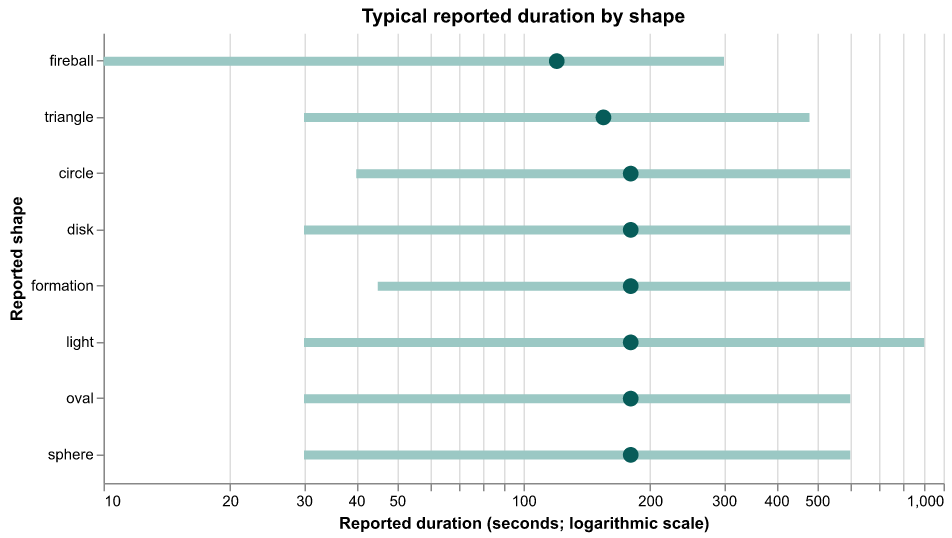

In [3]:
base = alt.Chart(summary).encode(
    y=alt.Y('shape:N', sort=shape_order, title='Reported shape'),
    tooltip=[alt.Tooltip('shape:N', title='Shape'),
             alt.Tooltip('reports:Q', title='Reports', format=','),
             alt.Tooltip('q1:Q', title='25th percentile (s)', format='.1f'),
             alt.Tooltip('median:Q', title='Median (s)', format='.1f'),
             alt.Tooltip('q3:Q', title='75th percentile (s)', format='.1f')])
intervals = base.mark_rule(strokeWidth=6, color='#9bc8c4').encode(
    x=alt.X('q1:Q', scale=alt.Scale(type='log', zero=False),
            title='Reported duration (seconds; logarithmic scale)'), x2='q3:Q')
dots = base.mark_circle(size=110, color='#075c59', opacity=1).encode(
    x=alt.X('median:Q', scale=alt.Scale(type='log', zero=False)))
duration_chart = (intervals + dots).properties(width=560, height=300,
    title='Typical reported duration by shape').configure_view(stroke=None)
display(duration_chart)
try:
    import vl_convert as vlc
    display(Image(vlc.vegalite_to_png(duration_chart.to_dict(), scale=1.5)))
except ImportError:
    print('Optional static preview skipped; use the interactive chart above.')

## Plot 2 · Does the monthly pattern change with shape?
The line-and-point chart shows each calendar month's share of the selected reports, pooling 2000–2013. Month is ordinal (`O`) in January–December order, and share is quantitative (`Q`) on a percent axis beginning at zero. A constant burnt-orange line and points connect months and support reading individual positions; color does not encode magnitude or shape. Python counts rows by shape and month and fills absent combinations with zero. In Vega-Lite, the dropdown filters those counts, aggregates over shapes when All eight shapes is selected, then recalculates the denominator and monthly shares. It therefore changes the plotted data, beyond tooltip or pan/zoom. Compare fireball with triangle, then reset to All eight shapes. Normalized shares allow groups of unequal size to be compared, while tooltips preserve the selected total and monthly count. Both charts use the same cohort, though this chart displays one shape at a time when filtered. Its y-axis stays fixed across selections so vertical positions remain comparable.

alt.Chart(...)

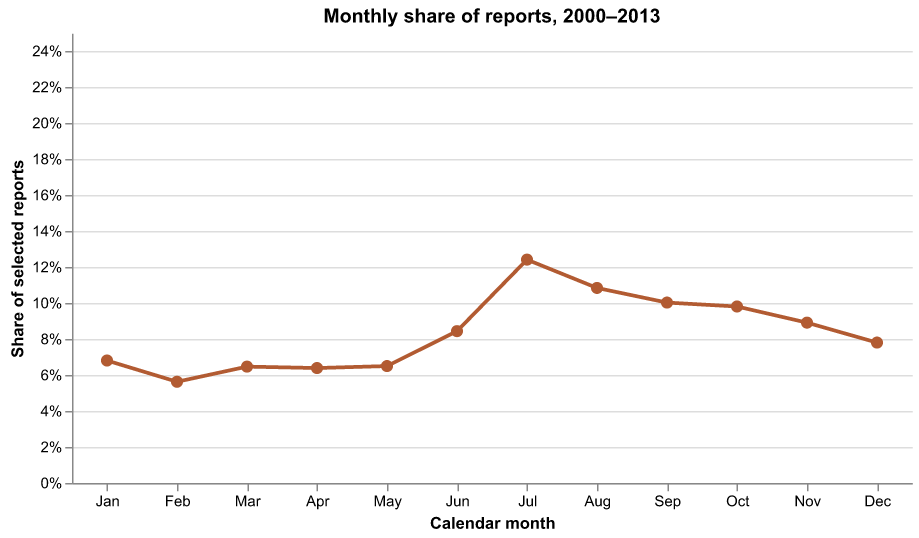

In [4]:
shape_choice = alt.param(name='shape_choice', value='All eight shapes',
    bind=alt.binding_select(options=['All eight shapes'] + sorted(shapes), name='Reported shape: '))
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
monthly_chart = (alt.Chart(monthly).add_params(shape_choice)
    .transform_filter((shape_choice == 'All eight shapes') | (alt.datum.shape == shape_choice))
    .transform_aggregate(reports='sum(reports)', groupby=['month'])
    .transform_joinaggregate(selected_total='sum(reports)')
    .transform_calculate(share='datum.reports / datum.selected_total')
    .mark_line(point=alt.OverlayMarkDef(filled=True, size=65, color='#b25b32'), color='#b25b32', strokeWidth=2.5)
    .encode(x=alt.X('month:O', sort=list(range(1,13)), title='Calendar month',
                   axis=alt.Axis(labelAngle=0, labelExpr=f'{json.dumps(month_names)}[datum.value-1]')),
            y=alt.Y('share:Q', title='Share of selected reports',
                    scale=alt.Scale(domain=[0, .25]), axis=alt.Axis(format='.0%')),
            tooltip=[alt.Tooltip('month:O', title='Month (1=Jan)'),
                     alt.Tooltip('reports:Q', title='Reports this month', format=','),
                     alt.Tooltip('selected_total:Q', title='Selected total', format=','),
                     alt.Tooltip('share:Q', title='Share', format='.1%')])
    .properties(width=560, height=300, title='Monthly share of reports, 2000–2013')
    .configure_view(stroke=None))
display(monthly_chart)
try:
    import vl_convert as vlc
    display(Image(vlc.vegalite_to_png(monthly_chart.to_dict(), scale=1.5)))
except ImportError:
    print('Optional static preview skipped; use the interactive chart above.')

## Interpretation and limits
The median-and-IQR view avoids letting extremely long duration claims determine the summary. The calendar view describes the timing of reports within a selected shape, without implying a causal seasonal process. Counts depend on archive coverage, reporting behavior, outdoor activity and label choices. Missing country/shape/duration information is excluded, so these views do not describe every archive row or all US sightings. Durations are unverified self-reports; the IQR is not a confidence interval. Aggregation pools years and does not correct for month length or observation effort. Percentages are shares of archive records, not population rates. The complete-year restriction avoids including only the early months of 2014.

In [5]:
assert int(summary.reports.sum()) == len(clean) == int(monthly.reports.sum())
assert len(summary) == 8 and len(monthly) == 96
assert ((summary.q1 > 0) & (summary.q1 <= summary['median'])
        & (summary['median'] <= summary.q3)).all()
for choice in ['All eight shapes'] + shapes:
    selected = monthly if choice == 'All eight shapes' else monthly[monthly['shape'].eq(choice)]
    totals = selected.groupby('month').reports.sum()
    assert len(totals) == 12 and totals.sum() > 0
    assert abs((totals / totals.sum()).sum() - 1) < 1e-12
    assert (totals / totals.sum()).max() < .25  # no clipping on the fixed axis
    print(choice, int(totals.sum()), 'reports; peak month', int(totals.idxmax()))
exports = Path('second_assignment_specs')
exports.mkdir(exist_ok=True)
duration_chart.save(exports / 'duration.json')
monthly_chart.save(exports / 'monthly.json')
print('CHECKS PASSED: common cohort, quartile order, all dropdown totals and shares, fixed-axis coverage.')
print('Exported both Vega-Lite specifications.')

All eight shapes 35417 reports; peak month 7
light 11254 reports; peak month 7
triangle 5029 reports; peak month 9
circle 4979 reports; peak month 7
fireball 4285 reports; peak month 7
sphere 3408 reports; peak month 7
disk 2490 reports; peak month 7
oval 2358 reports; peak month 7
formation 1614 reports; peak month 10
CHECKS PASSED: common cohort, quartile order, all dropdown totals and shares, fixed-axis coverage.
Exported both Vega-Lite specifications.
